In [2]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Environment is ready!")

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
NumPy: 2.5.3
Environment is ready!


## 1. Load MNIST

In [3]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()


train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Dataset downloaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Dataset downloaded successfully!
Training images: 60000
Testing images: 10000


## 2.Display handwritten digits

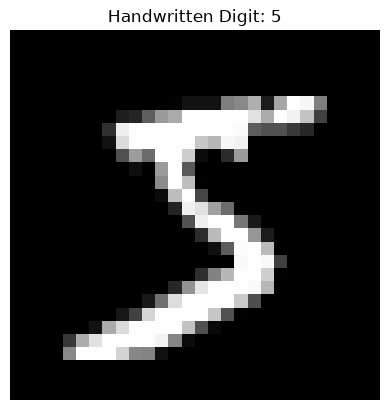

Image shape: torch.Size([1, 28, 28])
Correct label: 5


In [4]:
# Get one image and its correct label
image, label = train_dataset[0]

# Display the image
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Handwritten Digit: {label}")
plt.axis("off")
plt.show()

# Display image information
print("Image shape:", image.shape)
print("Correct label:", label)

## 3.Display handwritten digits

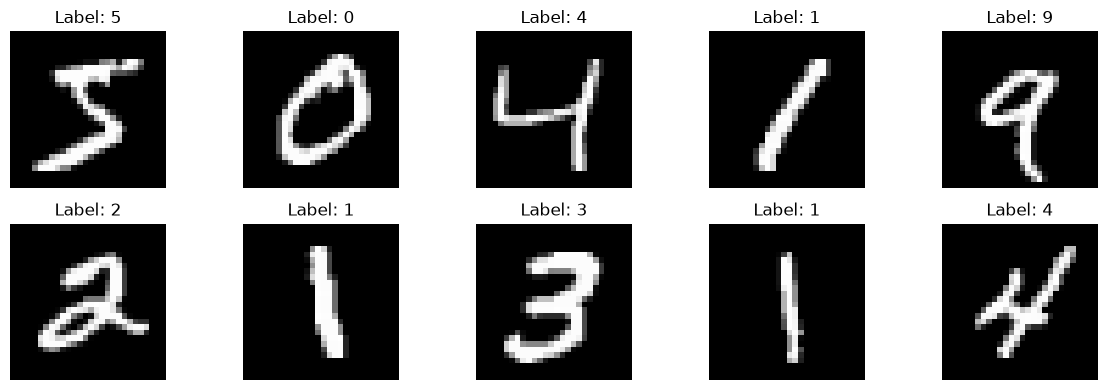

In [ ]:

plt.figure(figsize=(12, 4))

for i in range(10):
    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4.preparing data for CNN training

In [ ]:
from torch.utils.data import DataLoader

batch_size = 64


train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))
print("Dataset preparation completed!")

Training batches: 938
Testing batches: 157
Dataset preparation completed!


## 5.creation of CNN model

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class HandwrittenCNN(nn.Module):
    def __init__(self):
        super().__init__()

    
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        
        self.pool = nn.MaxPool2d(2, 2)

        
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

# Create the model
model = HandwrittenCNN()

print(model)
print("\nCNN model created successfully!")

HandwrittenCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

CNN model created successfully!


## 6. loss function

In [ ]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)
print("Training configuration ready!")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Training configuration ready!


## 7.Train the CNN model

In [ ]:

num_epochs = 5


train_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        
        optimizer.zero_grad()

        
        outputs = model(images)


        loss = criterion(outputs, labels)

        
        loss.backward()

        
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )

print("\nCNN training completed!")

Epoch [1/5], Loss: 0.2374
Epoch [2/5], Loss: 0.0658
Epoch [3/5], Loss: 0.0450
Epoch [4/5], Loss: 0.0342
Epoch [5/5], Loss: 0.0276

CNN training completed!


## 8. Testing the CNN Mode

In [ ]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)

    
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Total test images:", total)
print("Correct predictions:", correct)
print(f"Test Accuracy: {accuracy:.2f}%")

Total test images: 10000
Correct predictions: 9878
Test Accuracy: 98.78%


## 9.Generate a classification report

In [ ]:
from sklearn.metrics import classification_report


all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.numpy())

print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9829    0.9980    0.9904       980
           1     0.9878    0.9982    0.9930      1135
           2     0.9716    0.9932    0.9823      1032
           3     0.9843    0.9921    0.9882      1010
           4     0.9969    0.9817    0.9892       982
           5     0.9921    0.9854    0.9888       892
           6     0.9958    0.9854    0.9906       958
           7     0.9892    0.9825    0.9858      1028
           8     0.9937    0.9743    0.9839       974
           9     0.9861    0.9851    0.9856      1009

    accuracy                         0.9878     10000
   macro avg     0.9880    0.9876    0.9878     10000
weighted avg     0.9879    0.9878    0.9878     10000



## 10. Confusion Matrix

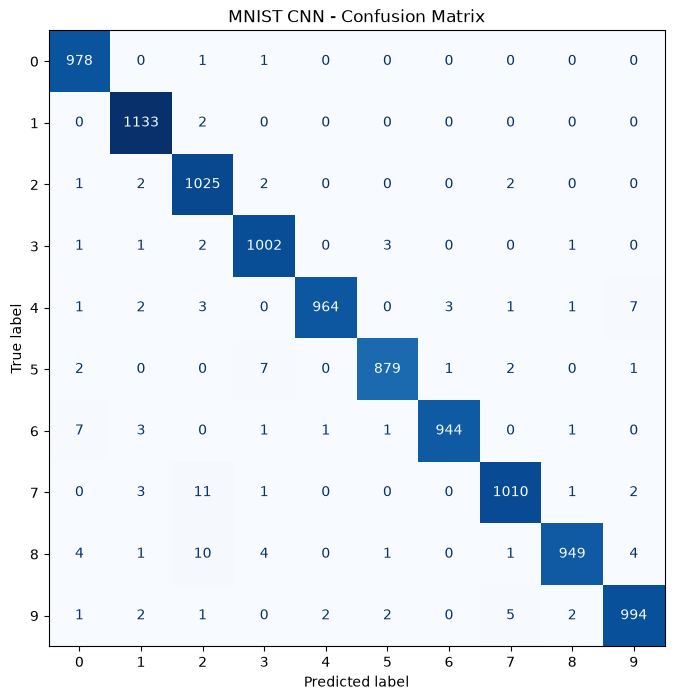

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(10, 8))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("MNIST CNN - Confusion Matrix")
plt.show()

## 11. Save the trained CNN model

In [ ]:

import torch
from pathlib import Path


Path("models").mkdir(exist_ok=True)


torch.save(
    model.state_dict(),
    "models/handwritten_cnn_mnist.pth"
)

print("Model saved successfully!")
print("Location: models/handwritten_cnn_mnist.pth")


Model saved successfully!
Location: models/handwritten_cnn_mnist.pth


## 12. Display a digit and predict

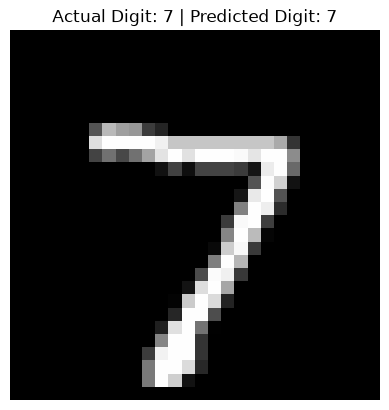

Actual digit: 7
Predicted digit: 7


In [ ]:

import matplotlib.pyplot as plt
import torch


image, actual_label = test_dataset[0]

model.eval()


with torch.no_grad():
    image_batch = image.unsqueeze(0)
    output = model(image_batch)
    predicted_label = output.argmax(dim=1).item()


plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual Digit: {actual_label} | Predicted Digit: {predicted_label}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_label)
print("Predicted digit:", predicted_label)


## 13. Test 10 handwritten digits

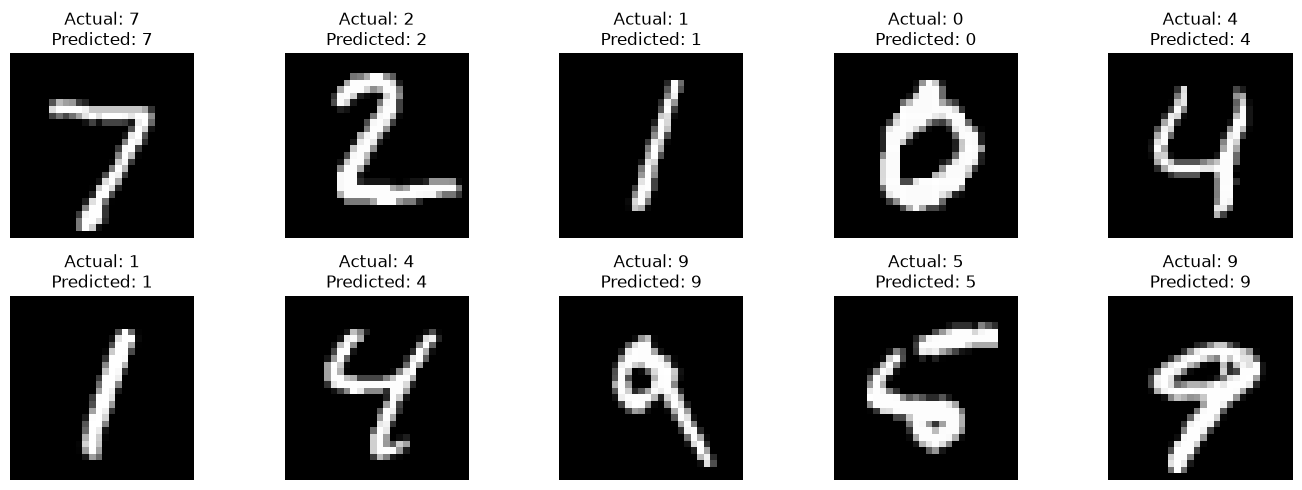

Correct predictions: 10 / 10


In [ ]:

import matplotlib.pyplot as plt
import torch

images = []
actual_labels = []

for i in range(10):
    image, label = test_dataset[i]
    images.append(image)
    actual_labels.append(label)


image_batch = torch.stack(images)

model.eval()

with torch.no_grad():
    outputs = model(image_batch)
    predictions = outputs.argmax(dim=1).tolist()


plt.figure(figsize=(14, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")

    actual = actual_labels[i]
    predicted = predictions[i]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Print the results
correct = sum(
    actual_labels[i] == predictions[i]
    for i in range(10)
)

print("Correct predictions:", correct, "/ 10")


## 14. Download the EMNIST Letters dataset

In [ ]:

from torchvision import datasets, transforms


letter_transform = transforms.ToTensor()

letter_train_dataset = datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=letter_transform
)


letter_test_dataset = datasets.EMNIST(
    root="./data",
    split="letters",
    train=False,
    download=True,
    transform=letter_transform
)

print("Letter training images:", len(letter_train_dataset))
print("Letter testing images:", len(letter_test_dataset))
print("Number of letter classes:", 26)


Letter training images: 124800
Letter testing images: 20800
Number of letter classes: 26


## 15. Prepare the letter dataset

In [ ]:

from torch.utils.data import Dataset, DataLoader


class LetterDataset(Dataset):
    def __init__(self, original_dataset):
        self.original_dataset = original_dataset

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, index):
        image, label = self.original_dataset[index]
        return image, label - 1


letter_train = LetterDataset(letter_train_dataset)
letter_test = LetterDataset(letter_test_dataset)


batch_size = 64

letter_train_loader = DataLoader(
    letter_train,
    batch_size=batch_size,
    shuffle=True
)

letter_test_loader = DataLoader(
    letter_test,
    batch_size=batch_size,
    shuffle=False
)


image, label = letter_train[0]

print("Image shape:", image.shape)
print("Corrected label:", label)
print("Minimum possible label: 0")
print("Maximum possible label: 25")


Image shape: torch.Size([1, 28, 28])
Corrected label: 22
Minimum possible label: 0
Maximum possible label: 25


## 16.Display handwritten letters

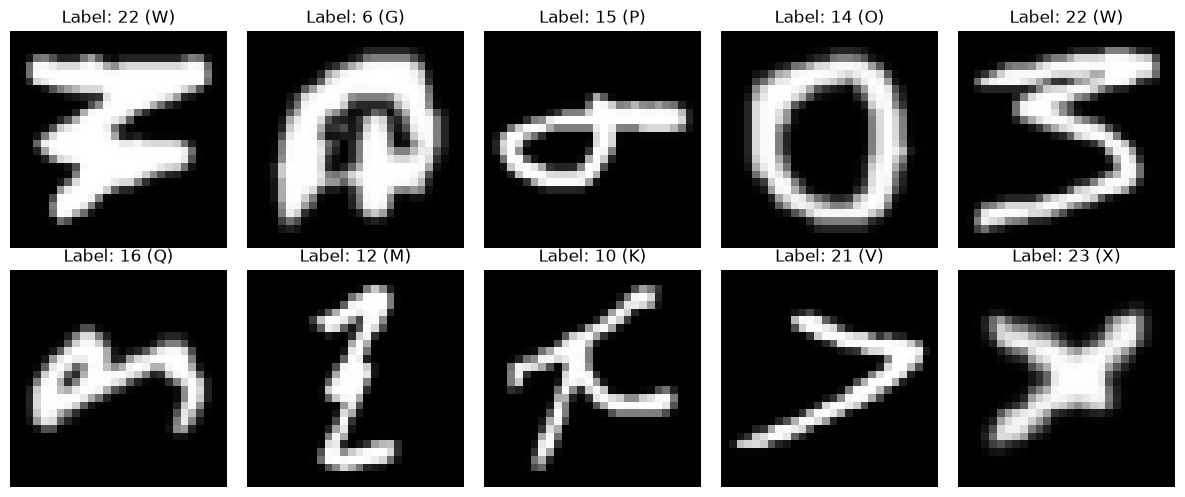

In [ ]:

import matplotlib.pyplot as plt
import string


plt.figure(figsize=(12, 5))

for i in range(10):
    image, label = letter_train[i]


    letter = string.ascii_uppercase[label]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {label} ({letter})")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 17. Create the letter-recognition CNN

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class LetterCNN(nn.Module):
    def __init__(self):
        super().__init__()

        
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        
        self.pool = nn.MaxPool2d(2, 2)

        
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 26)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x



letter_model = LetterCNN()

print("Letter CNN created successfully!")
print("Number of output classes:", 26)
print("Model device: CPU")


Letter CNN created successfully!
Number of output classes: 26
Model device: CPU


## 18. Prepare training settings

In [ ]:

criterion = nn.CrossEntropyLoss()

letter_optimizer = torch.optim.Adam(
    letter_model.parameters(),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Ready to train the letter model!")


Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Ready to train the letter model!


## 19. Train the letter-recognition CNN

In [ ]:

num_epochs = 5

for epoch in range(num_epochs):
    letter_model.train()

    running_loss = 0.0
    total_samples = 0
    correct_predictions = 0

    for images, labels in letter_train_loader:
        
        letter_optimizer.zero_grad()

        
        outputs = letter_model(images)

        
        loss = criterion(outputs, labels)

    
        loss.backward()

    
        letter_optimizer.step()

        
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        total_samples += labels.size(0)
        correct_predictions += (
            predictions == labels
        ).sum().item()

    epoch_loss = running_loss / total_samples
    epoch_accuracy = 100 * correct_predictions / total_samples

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Training Accuracy: {epoch_accuracy:.2f}%"
    )

print("Letter model training complete!")



Epoch [1/5] Loss: 0.5459 Training Accuracy: 83.14%
Epoch [2/5] Loss: 0.2668 Training Accuracy: 91.27%
Epoch [3/5] Loss: 0.2224 Training Accuracy: 92.54%
Epoch [4/5] Loss: 0.1949 Training Accuracy: 93.37%
Epoch [5/5] Loss: 0.1756 Training Accuracy: 94.00%
Letter model training complete!


## 20. Evaluate the letter model

In [ ]:

letter_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in letter_test_loader:
        outputs = letter_model(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

test_accuracy = 100 * correct / total

print("Total test images:", total)
print("Correct predictions:", correct)
print(f"Letter Test Accuracy: {test_accuracy:.2f}%")



Total test images: 20800
Correct predictions: 19300
Letter Test Accuracy: 92.79%


## 21. Save the letter-recognition model

In [ ]:

from pathlib import Path
import torch


Path("models").mkdir(exist_ok=True)


torch.save(
    letter_model.state_dict(),
    "models/handwritten_letters_cnn.pth"
)

print("Letter model saved successfully!")
print("Location: models/handwritten_letters_cnn.pth")


Letter model saved successfully!
Location: models/handwritten_letters_cnn.pth


## 22. Test individual handwritten letters

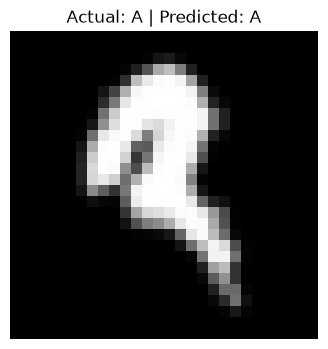

Actual letter: A
Predicted letter: A


In [ ]:

import matplotlib.pyplot as plt
import string
import torch

image, actual_label = letter_test[0]


letter_model.eval()

with torch.no_grad():
    image_batch = image.unsqueeze(0)
    output = letter_model(image_batch)
    predicted_label = output.argmax(dim=1).item()


actual_letter = string.ascii_uppercase[actual_label]
predicted_letter = string.ascii_uppercase[predicted_label]

plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {actual_letter} | Predicted: {predicted_letter}"
)
plt.axis("off")
plt.show()

print("Actual letter:", actual_letter)
print("Predicted letter:", predicted_letter)


## 23. Test 10 handwritten letters

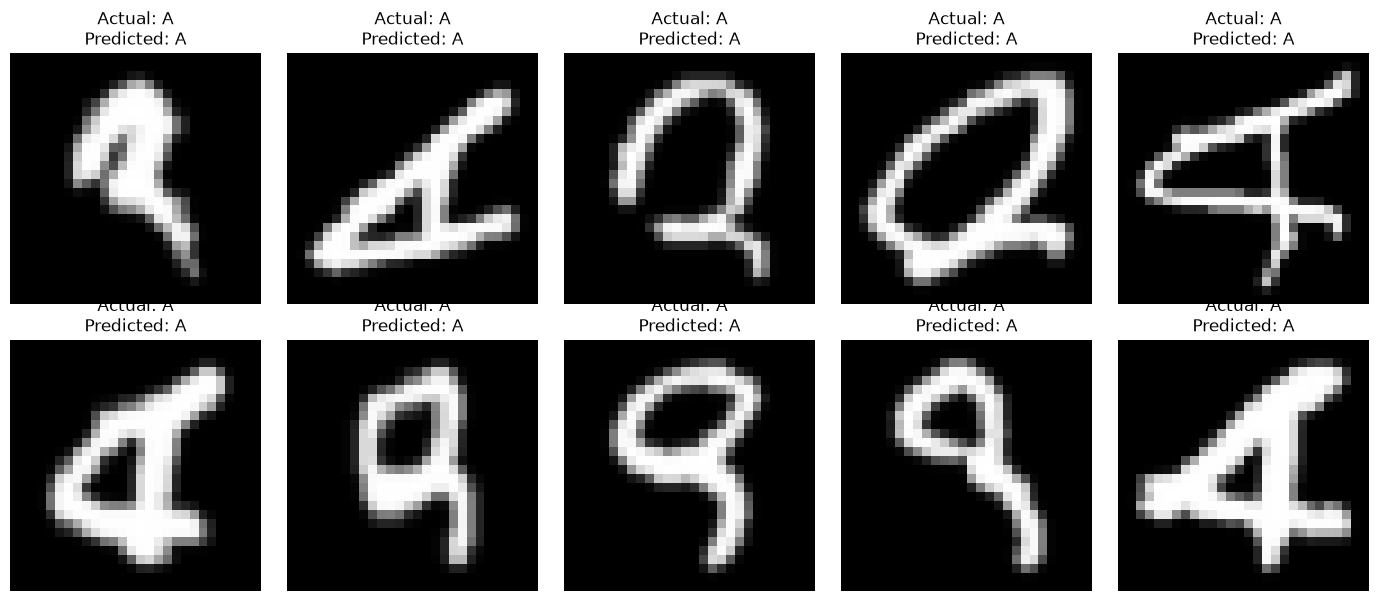

Correct predictions: 10/10
Accuracy on these 10 images: 100%


In [26]:

import matplotlib.pyplot as plt
import string
import torch

letter_model.eval()

plt.figure(figsize=(14, 6))
correct = 0

with torch.no_grad():
    for i in range(10):
        image, actual_label = letter_test[i]

        output = letter_model(image.unsqueeze(0))
        predicted_label = output.argmax(dim=1).item()

        actual_letter = string.ascii_uppercase[actual_label]
        predicted_letter = string.ascii_uppercase[predicted_label]

        if actual_label == predicted_label:
            correct += 1

        plt.subplot(2, 5, i + 1)
        plt.imshow(image.squeeze(), cmap="gray")
        plt.title(
            f"Actual: {actual_letter}\nPredicted: {predicted_letter}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct predictions: {correct}/10")
print(f"Accuracy on these 10 images: {correct * 10}%")


## 24. Generate the classification report

In [ ]:

from sklearn.metrics import classification_report
import string
import torch

all_letter_labels = []
all_letter_predictions = []

letter_model.eval()

with torch.no_grad():
    for images, labels in letter_test_loader:
        outputs = letter_model(images)
        predictions = outputs.argmax(dim=1)

        all_letter_labels.extend(labels.tolist())
        all_letter_predictions.extend(predictions.tolist())


letter_names = list(string.ascii_uppercase)

print("Letter Recognition Classification Report")
print(
    classification_report(
        all_letter_labels,
        all_letter_predictions,
        labels=list(range(26)),
        target_names=letter_names,
        digits=4,
        zero_division=0
    )
)


Letter Recognition Classification Report
              precision    recall  f1-score   support

           A     0.0000    0.0000    0.0000       800
           B     0.0000    0.0000    0.0000       800
           C     0.0000    0.0000    0.0000       800
           D     0.0000    0.0000    0.0000       800
           E     0.0000    0.0000    0.0000       800
           F     0.0000    0.0000    0.0000       800
           G     0.0000    0.0000    0.0000       800
           H     0.0000    0.0000    0.0000       800
           I     0.0000    0.0000    0.0000       800
           J     0.0000    0.0000    0.0000       800
           K     0.0383    0.7362    0.0729       800
           L     0.0000    0.0000    0.0000       800
           M     0.0000    0.0000    0.0000       800
           N     0.0000    0.0000    0.0000       800
           O     0.0135    0.0875    0.0234       800
           P     0.0000    0.0000    0.0000       800
           Q     0.0000    0.0000    0.0

## 25. predicted different ltter

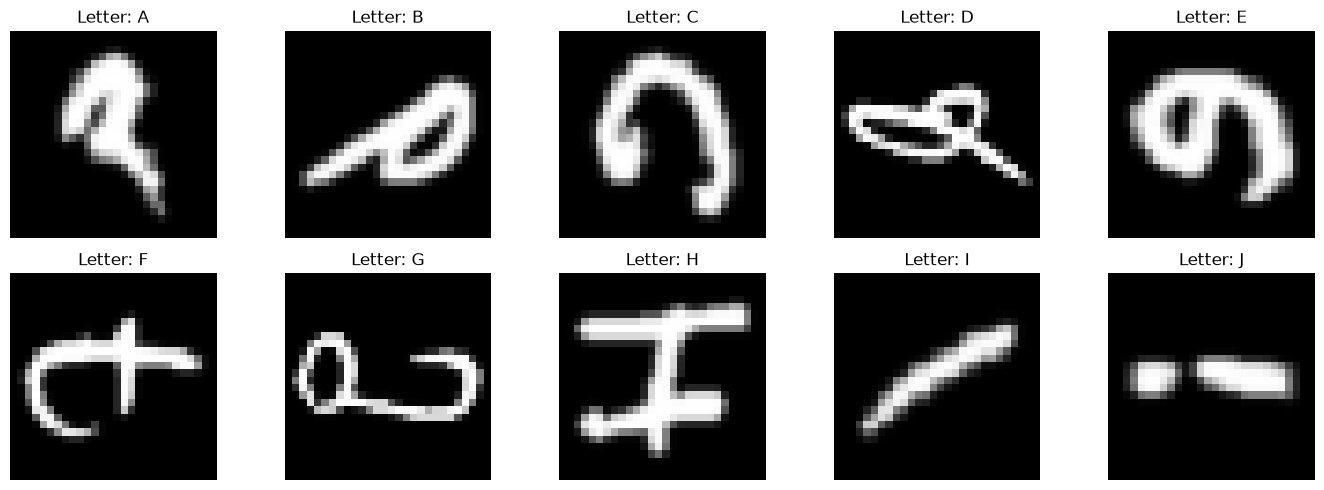

In [ ]:

import matplotlib.pyplot as plt
import string

plt.figure(figsize=(14, 5))


shown = 0
found_letters = set()

for i in range(len(letter_test)):
    image, label = letter_test[i]

    if label not in found_letters:
        found_letters.add(label)

        letter = string.ascii_uppercase[label]

        plt.subplot(2, 5, shown + 1)
        plt.imshow(image.squeeze(), cmap="gray")
        plt.title(f"Letter: {letter}")
        plt.axis("off")

        shown += 1

        if shown == 10:
            break

plt.tight_layout()
plt.show()


### 26.Model prediction on different letter and correct display

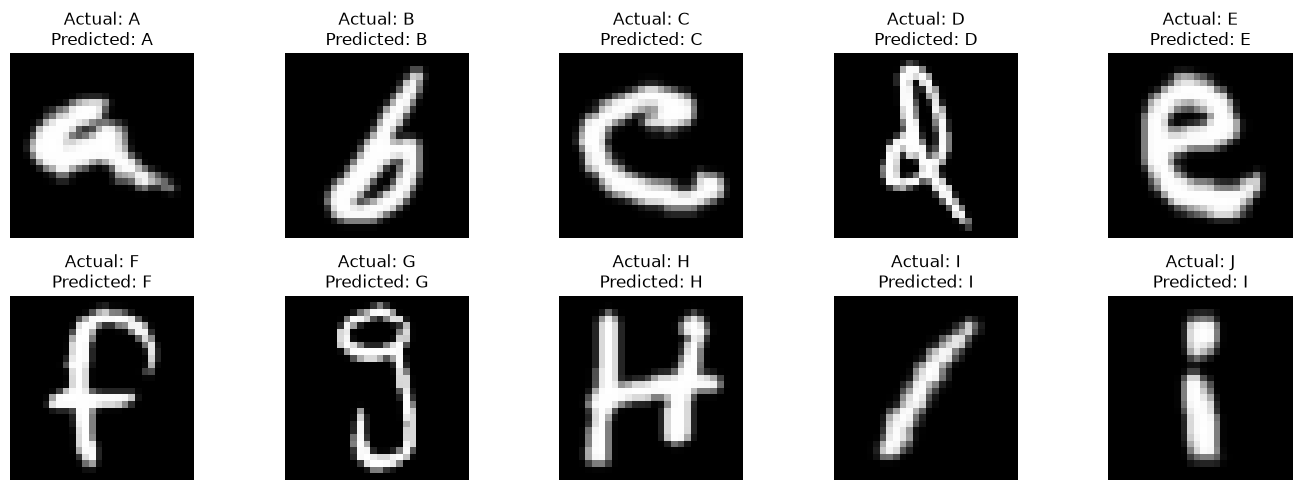

Correct predictions: 9/10


In [30]:

import torch
import string
import matplotlib.pyplot as plt

letter_model.eval()
shown = 0
found_letters = set()
correct = 0

plt.figure(figsize=(14, 5))

with torch.no_grad():
    for i in range(len(letter_test)):
        image, actual_label = letter_test[i]

        if actual_label in found_letters:
            continue

        found_letters.add(actual_label)

        output = letter_model(image.unsqueeze(0))
        predicted_label = output.argmax(dim=1).item()

        actual_letter = string.ascii_uppercase[actual_label]
        predicted_letter = string.ascii_uppercase[predicted_label]

        if actual_label == predicted_label:
            correct += 1

        plt.subplot(2, 5, shown + 1)
        plt.imshow(image.squeeze().T, cmap="gray")
        plt.title(
            f"Actual: {actual_letter}\nPredicted: {predicted_letter}"
        )
        plt.axis("off")

        shown += 1

        if shown == 10:
            break

plt.tight_layout()
plt.show()

print(f"Correct predictions: {correct}/{shown}")


## 27. Generate the full classification report

In [31]:

from sklearn.metrics import classification_report
import string
import torch

all_letter_labels = []
all_letter_predictions = []

letter_model.eval()

with torch.no_grad():
    for images, labels in letter_test_loader:
        outputs = letter_model(images)
        predictions = outputs.argmax(dim=1)

        all_letter_labels.extend(labels.tolist())
        all_letter_predictions.extend(predictions.tolist())

print("Letter Recognition Classification Report\n")

print(
    classification_report(
        all_letter_labels,
        all_letter_predictions,
        labels=list(range(26)),
        target_names=list(string.ascii_uppercase),
        digits=4,
        zero_division=0
    )
)


Letter Recognition Classification Report

              precision    recall  f1-score   support

           A     0.9025    0.9487    0.9250       800
           B     0.9730    0.9463    0.9594       800
           C     0.9407    0.9712    0.9557       800
           D     0.9699    0.9275    0.9482       800
           E     0.9666    0.9413    0.9538       800
           F     0.9820    0.9550    0.9683       800
           G     0.8182    0.8325    0.8253       800
           H     0.8981    0.9475    0.9221       800
           I     0.7017    0.8175    0.7552       800
           J     0.9474    0.9450    0.9462       800
           K     0.9677    0.9375    0.9524       800
           L     0.7638    0.6750    0.7167       800
           M     0.9858    0.9575    0.9715       800
           N     0.8846    0.9675    0.9242       800
           O     0.9592    0.9688    0.9639       800
           P     0.9681    0.9850    0.9765       800
           Q     0.8759    0.7937    0.

## 28. Create the confusion matrix

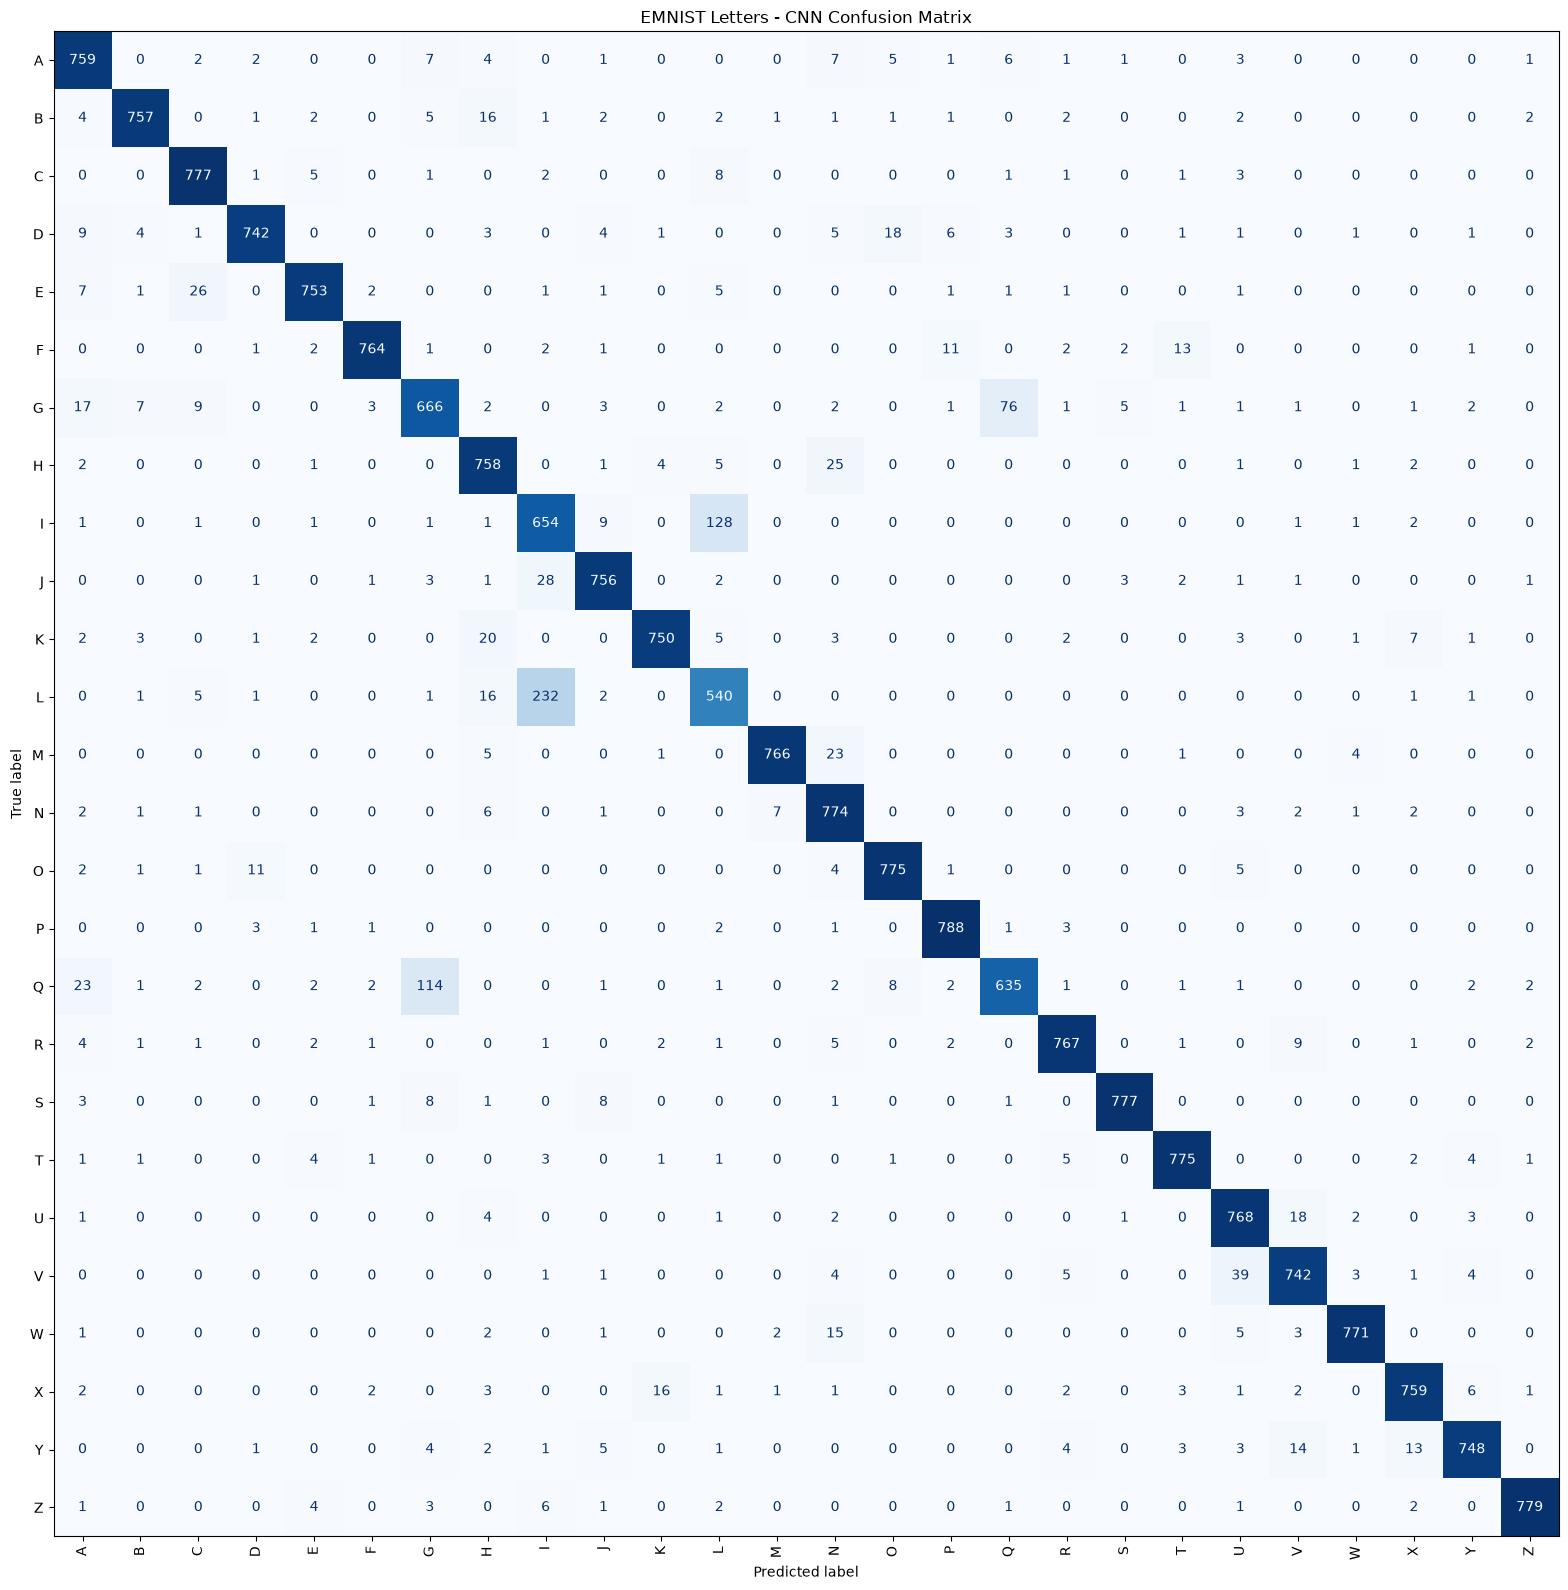

In [ ]:

import matplotlib.pyplot as plt
import string
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(
    all_letter_labels,
    all_letter_predictions,
    labels=list(range(26))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(string.ascii_uppercase)
)

fig, ax = plt.subplots(figsize=(16, 16))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation="vertical"
)

plt.title("EMNIST Letters - CNN Confusion Matrix")
plt.tight_layout()
plt.show()


## 29. Save classification report to a file

In [ ]:

from pathlib import Path
from sklearn.metrics import classification_report
import string


Path("results").mkdir(exist_ok=True)


report = classification_report(
    all_letter_labels,
    all_letter_predictions,
    labels=list(range(26)),
    target_names=list(string.ascii_uppercase),
    digits=4,
    zero_division=0
)


report_path = Path("results/letter_classification_report.txt")
report_path.write_text(report, encoding="utf-8")

print("Classification report saved successfully!")
print("Location:", report_path)


Classification report saved successfully!
Location: results\letter_classification_report.txt


## 30. confusion matrix image

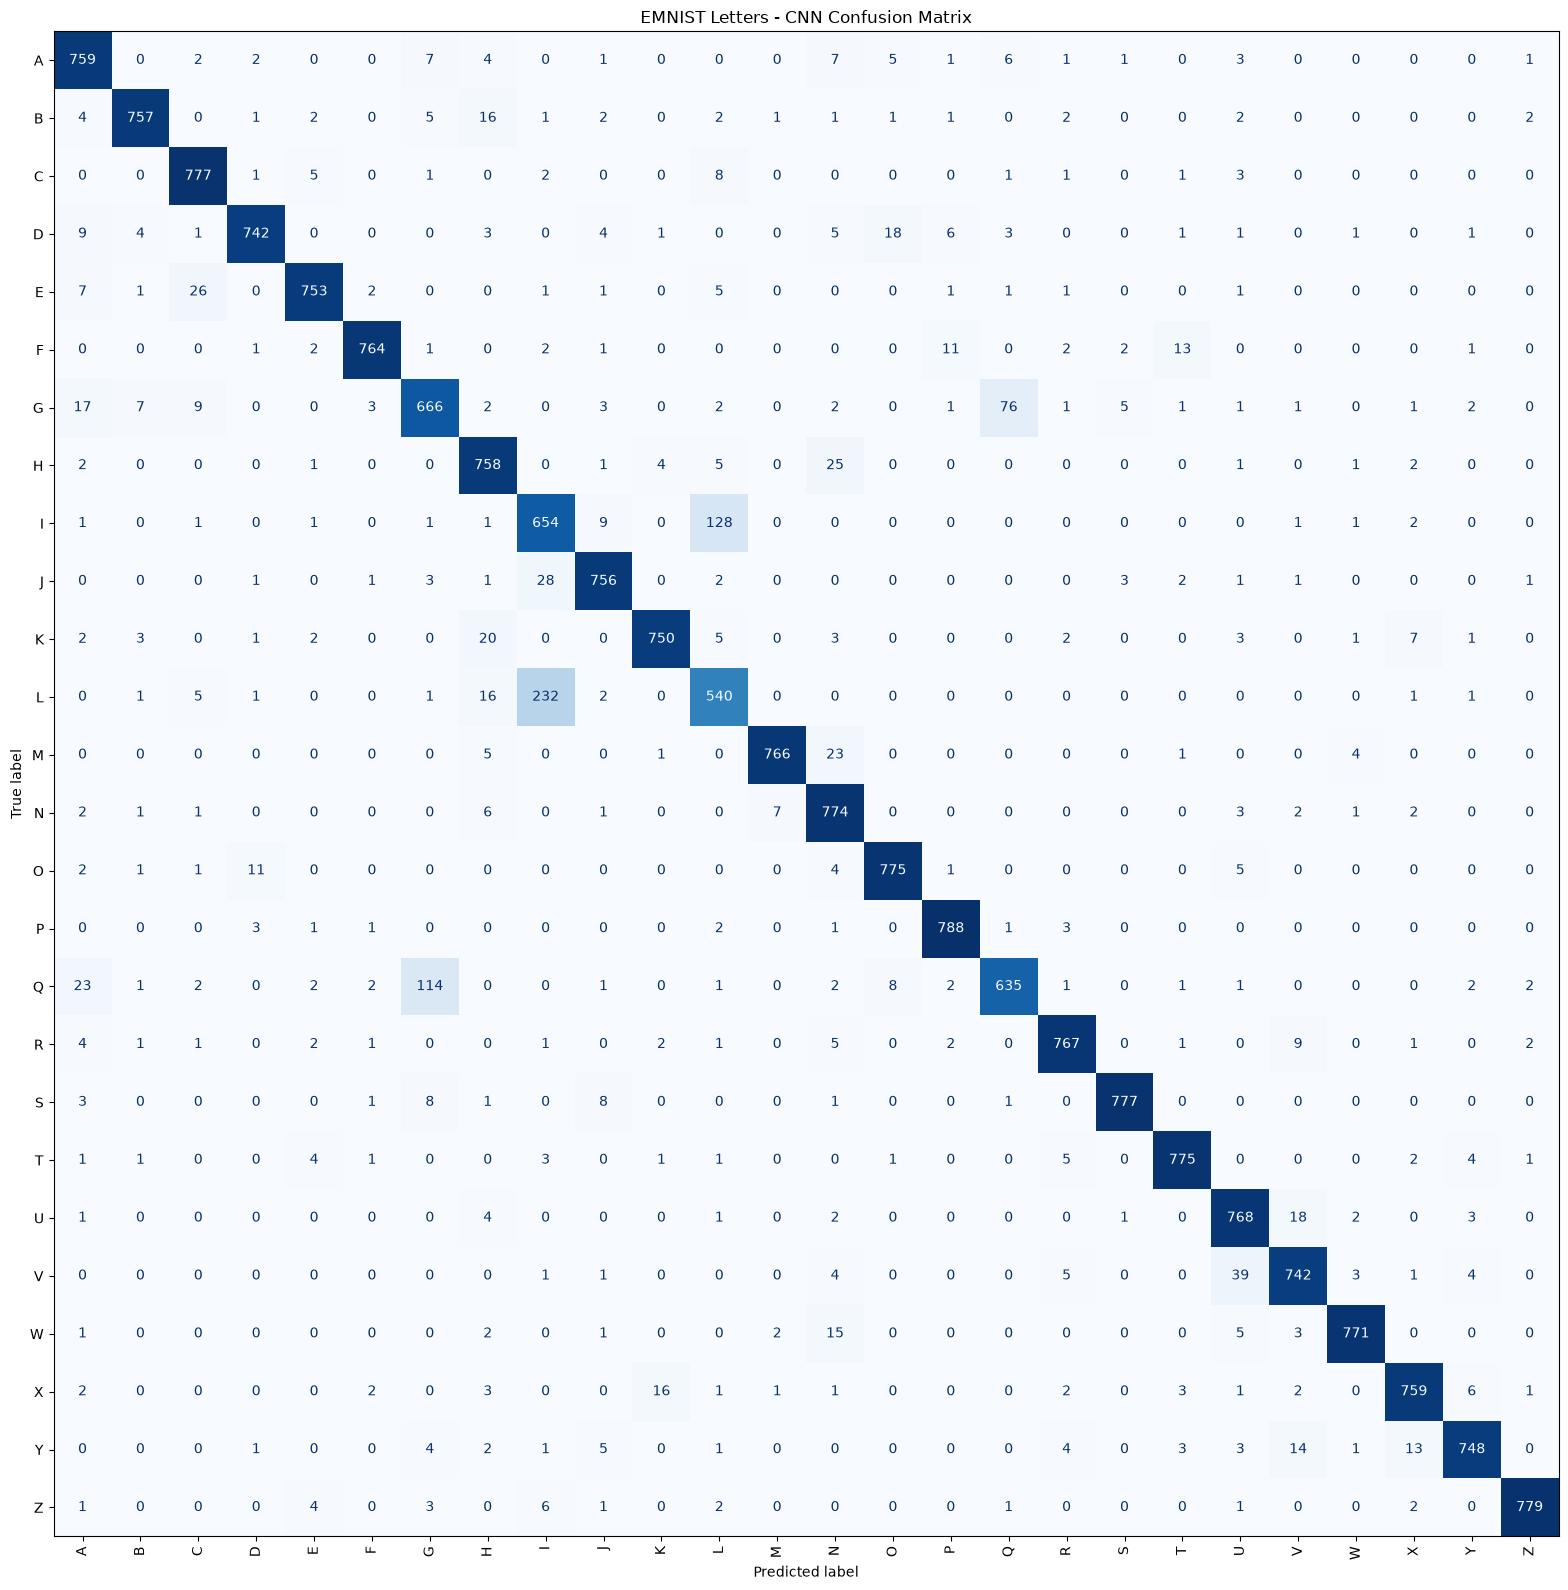

Confusion matrix saved successfully!
Location: results\letter_confusion_matrix.png


In [34]:

from pathlib import Path
import matplotlib.pyplot as plt
import string
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create results folder
Path("results").mkdir(exist_ok=True)

# Calculate the confusion matrix
cm = confusion_matrix(
    all_letter_labels,
    all_letter_predictions,
    labels=list(range(26))
)

# Plot the matrix
fig, ax = plt.subplots(figsize=(16, 16))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(string.ascii_uppercase)
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation="vertical"
)

plt.title("EMNIST Letters - CNN Confusion Matrix")
plt.tight_layout()

# Save the image
output_path = Path("results/letter_confusion_matrix.png")

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Confusion matrix saved successfully!")
print("Location:", output_path)
